# EDA workstream E — regions, completeness and discrepancy

Owner: Project 5. Question: where do neurons and synapses sit, how complete is the record, and how often does an edge recur in another copy?

FAFB only for now. E6 and the malecns side of every item need the MaleCNS cache (neuPrint token) and the hemibrain.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
import pandas as pd
from IPython.display import Image, display
from src.fetch_fafb import load_neurons, load_edges, load_edgeroi, raw_file
from src import eda_e_figures as F
neurons, edges, edgeroi = load_neurons(), load_edges(), load_edgeroi()
STATS = {}

## E1. One neuron, one region (D15, D17)

{
 "neurons": 45168,
 "no_synapses": 318,
 "median_top_share": 0.5601480919796453,
 "gap_below_0.10": 11268,
 "gap_below_0.10_pct": 24.946865037194474
}


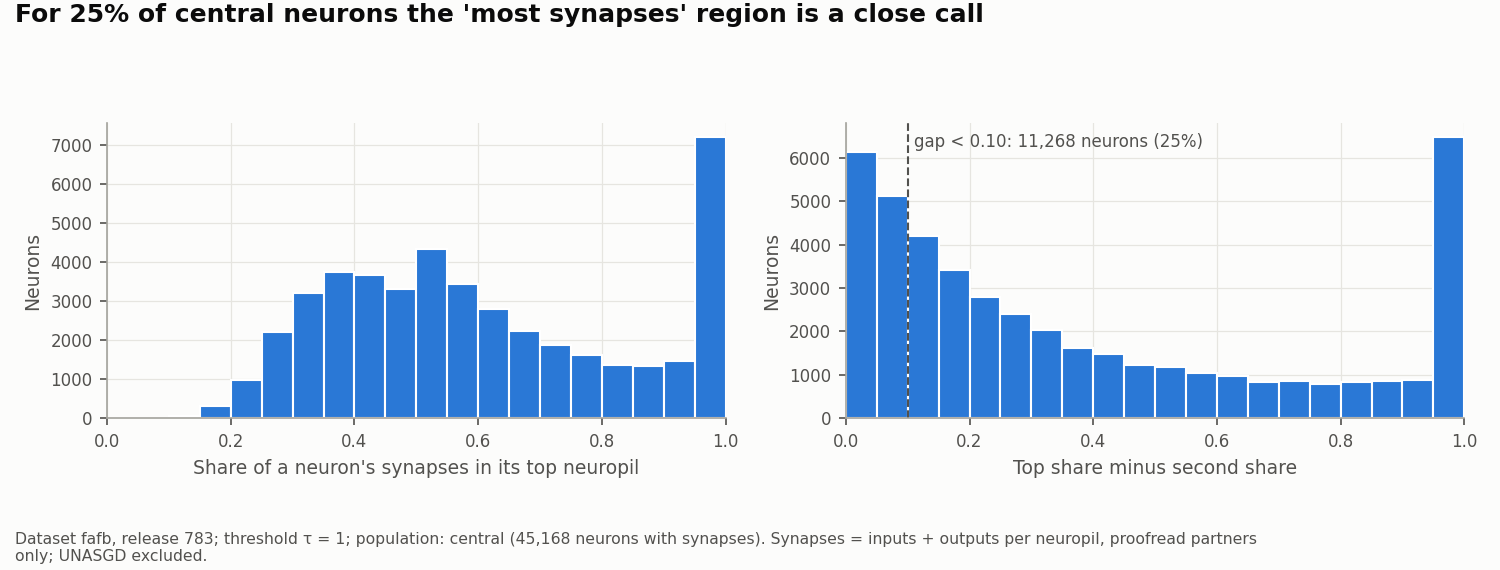

,neuron_id,cell_type,edges,input_synapses,top_frac_in,sum_of_fractions
0,720575940614297640,EPG,before (τ = 1),256,"EB 0.84, PB 0.11, FB 0.02",1.0
1,720575940614297640,EPG,after (τ = 10),32,"EB 0.81, GA_L 0.12, FB 0.06",1.0
2,720575940605213100,JO-DA,before (τ = 1),8,"AMMC_L 0.50, SAD 0.50",1.0
3,720575940605213100,JO-DA,after (τ = 10),0,—,0.0
4,720575940600646173,JO-EV6,before (τ = 1),57,"AMMC_L 0.56, SAD 0.44",1.0
5,720575940600646173,JO-EV6,after (τ = 10),0,—,0.0


In [3]:
paths, st, tabs = F.fig_e1(neurons, edges, edgeroi)
STATS['E1'] = st
print(json.dumps(st, indent=1, default=float))
for p in paths:
    display(Image(filename=str(p)))
display(tabs['worked_example'])

## E2. The optic-lobe share (D13, D14)

{
 "neurons": 139262,
 "clean central": 42100,
 "ambiguous": 5947,
 "clean optic": 90588,
 "no synapses": 627,
 "optic_by_super_class_pct": 55.679941405408506,
 "optic_by_region_flag_pct": 67.33782367049159,
 "optic_by_synapse_share_pct": 65.04861340494894,
 "ambiguous_pct": 4.270368083181342
}


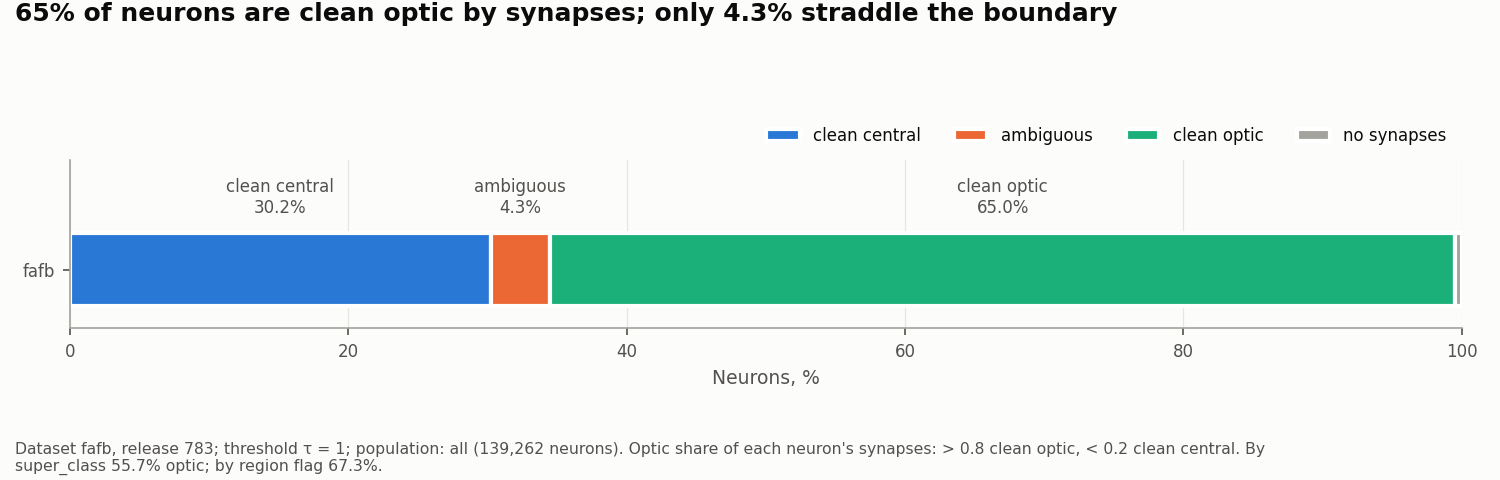

In [4]:
paths, st, tabs = F.fig_e2(neurons, edgeroi)
STATS['E2'] = st
print(json.dumps(st, indent=1, default=float))
for p in paths:
    display(Image(filename=str(p)))

## E3. The region-to-region map

{
 "regions": 38,
 "within_region_share": 0.5938392332902658,
 "synapses": 13378205
}


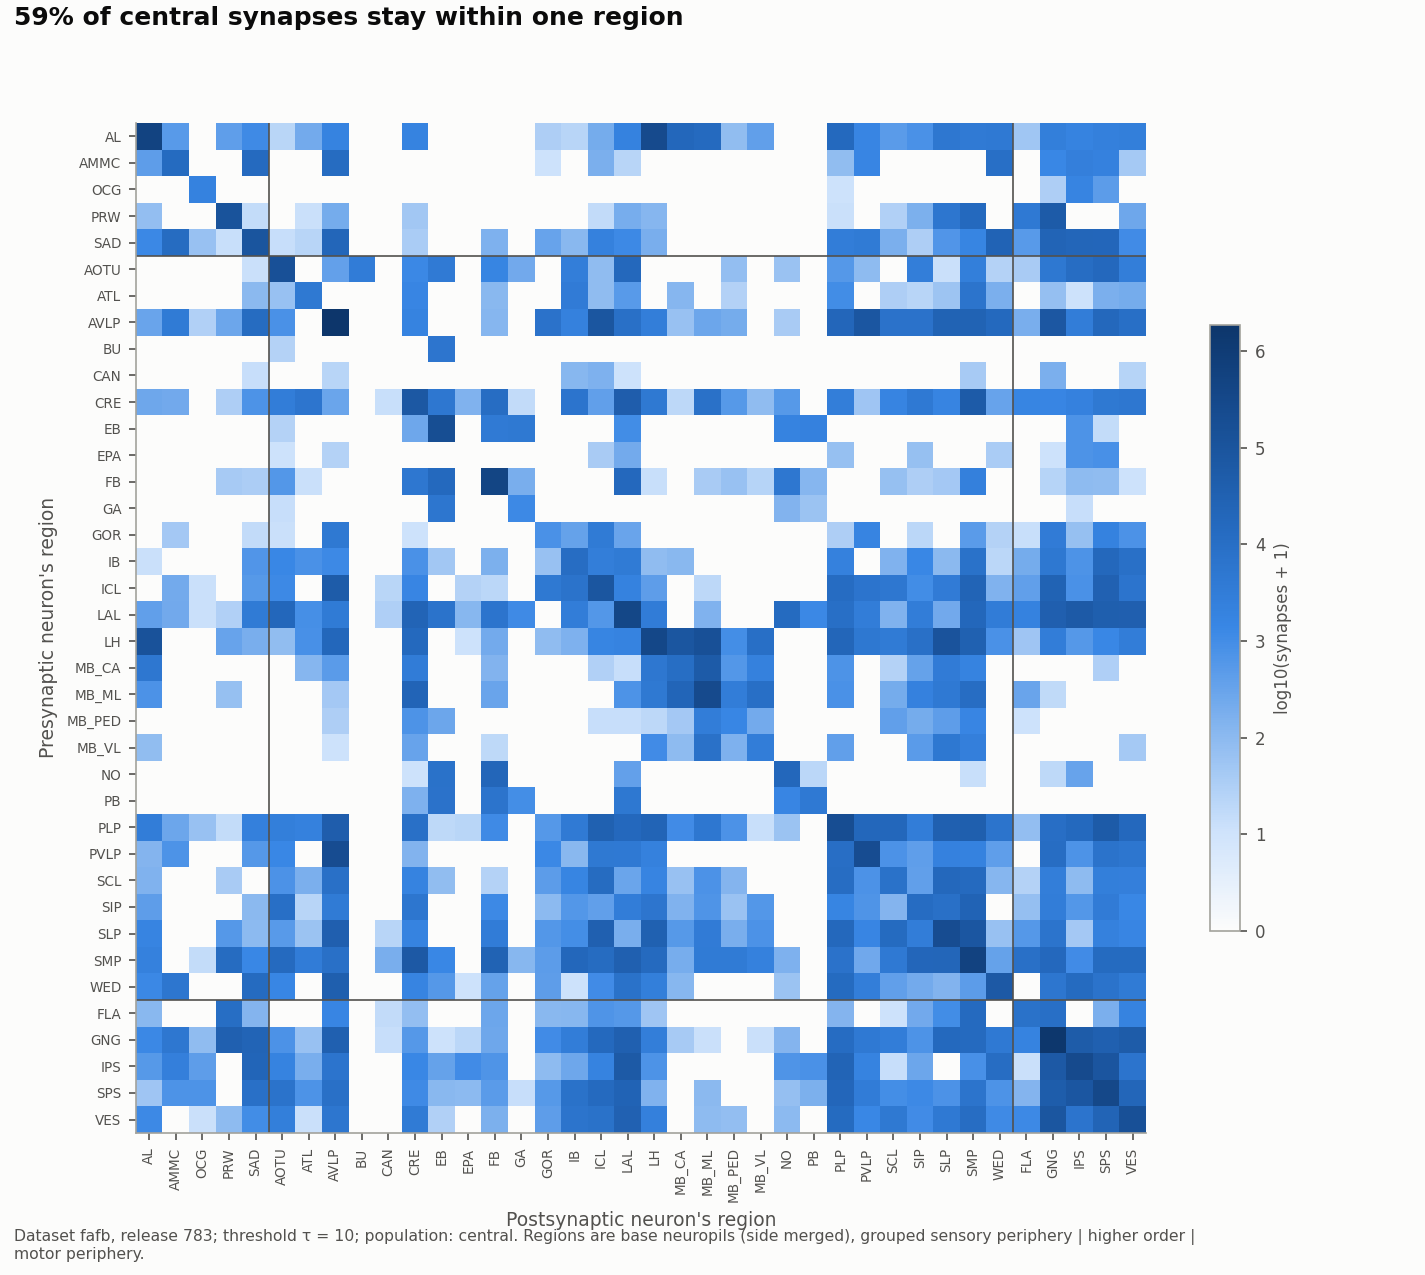

In [5]:
paths, st, tabs = F.fig_e3(neurons, edges)
STATS['E3'] = st
print(json.dumps(st, indent=1, default=float))
for p in paths:
    display(Image(filename=str(p)))

## E4. How complete is each neuron's record (FAFB supplement; the plan's E4 is malecns)

{
 "neurons": 45109,
 "median_ratio": 0.9516129032258065,
 "pooled_ratio": 0.9508321025098919,
 "over_1": 0
}


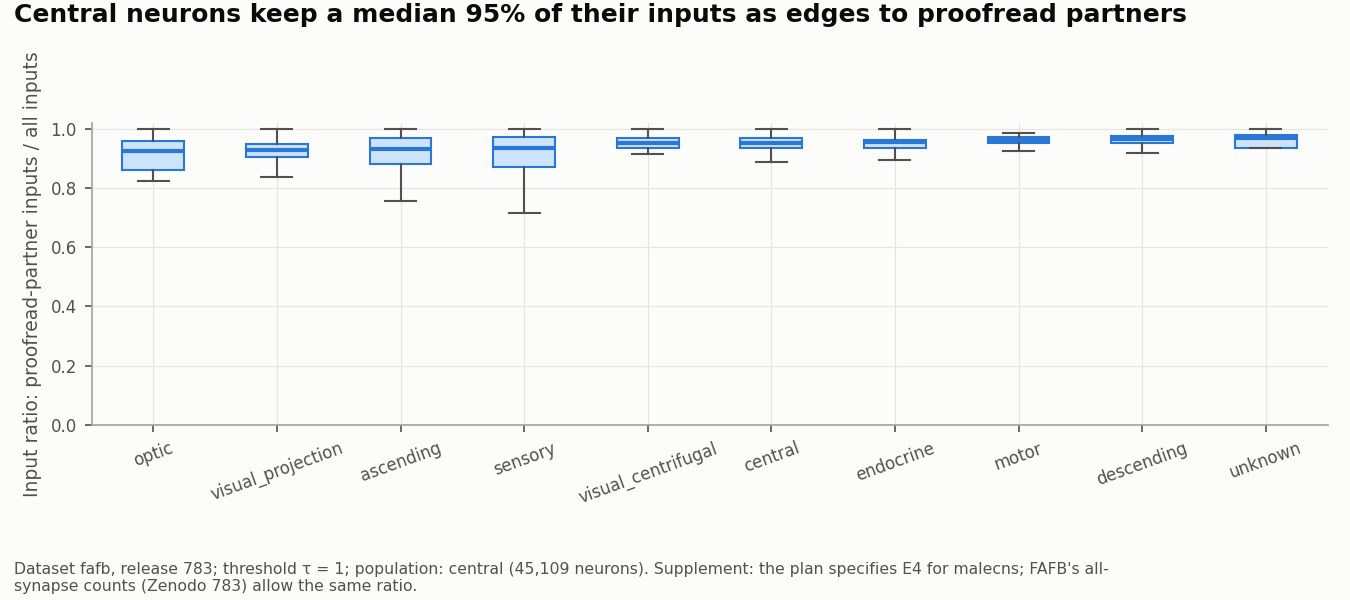

In [6]:
paths, st, tabs = F.fig_e4_fafb(neurons, edges, pd.read_feather(raw_file('neuropil_post')))
STATS['E4'] = st
print(json.dumps(st, indent=1, default=float))
for p in paths:
    display(Image(filename=str(p)))

## E5. Does an edge recur on the other side (D10)

{
 "central": {
  "type_pairs": 1656860,
  "share_1syn": 0.3151210402960113,
  "share_10plus": 0.9622144006192774
 },
 "optic": {
  "type_pairs": 87960,
  "share_1syn": 0.4606385474854796,
  "share_10plus": 0.9744367417677643
 }
}


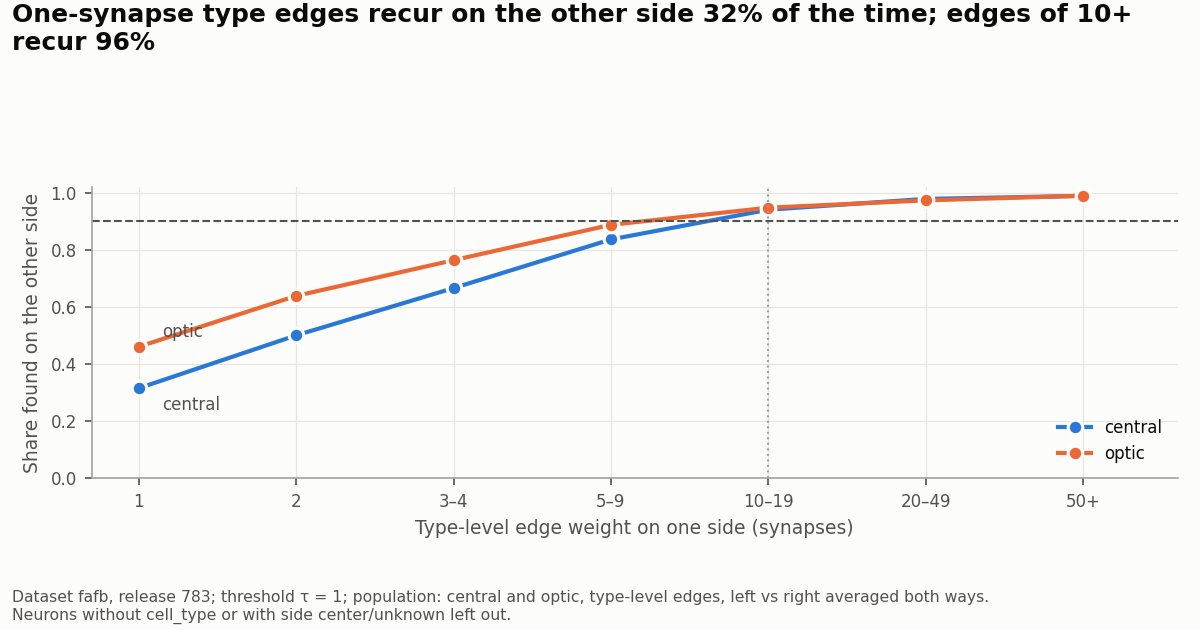

central                         optic                       
        share pairs_left pairs_right  share pairs_left pairs_right
bin                                                               
1       0.315     499460      511873  0.461      15254       15074
2       0.500     178810      185746  0.639       7849        7695
3–4     0.666     150294      158536  0.764       9010        8449
5–9     0.837     127035      137096  0.888      10341        9970
10–19   0.941      76172       84060  0.948       8399        8208
20–49   0.979      53294       59349  0.974       8692        8534
50+     0.990      27366       30467  0.990      13846       14637

,type_pairs,1,2,3–4,5–9,10–19,20–49,50+
min side count 0,23212,0.000,0.000,0.000,0.000,0.000,0.000,0.000
min side count 1,1327266,0.312,0.500,0.668,0.841,0.949,0.986,0.996
2–4,297250,0.346,0.530,0.690,0.858,0.952,0.988,0.997
5–19,8699,0.418,0.605,0.749,0.876,0.956,0.976,0.995
20+,433,0.557,0.735,0.837,0.948,0.987,1.000,1.000


,type_pairs,1,2,3–4,5–9,10–19,20–49,50+
all types,1656860,0.315,0.500,0.666,0.837,0.941,0.979,0.990
both types on both sides,1633648,0.319,0.506,0.673,0.845,0.950,0.987,0.996
equal left/right counts,1059871,0.320,0.514,0.686,0.860,0.961,0.991,0.999
"hemibrain-matched, both sides",843048,0.327,0.516,0.684,0.856,0.956,0.989,0.997


In [7]:
paths, st, tabs = F.fig_e5(neurons, edges)
STATS['E5'] = st
print(json.dumps(st, indent=1, default=float))
for p in paths:
    display(Image(filename=str(p)))
display(pd.concat(tabs, axis=1).round(3))
from src.eda_e import e5_by_type_size, e5_restricted
display(e5_by_type_size(neurons, edges))  # recurrence rises with type size
display(e5_restricted(neurons, edges))    # restricting the type set barely moves it

## E6. Does an edge recur in another animal

Pending: needs the malecns cache (neuPrint token) and the hemibrain.

## E7. Central complex profile

{
 "neurons_region_cx": 2617,
 "neurons_cell_class_cx": 2875,
 "overlap": 2560,
 "cell_types": 223,
 "untyped": 10,
 "types_with_8_to_16_per_side": 39,
 "types_one_per_side": 63,
 "edges_at_tau": 66982,
 "columnar_block_fill_median": 0.02976190476190476,
 "columnar_connected_type_pairs": 369
}


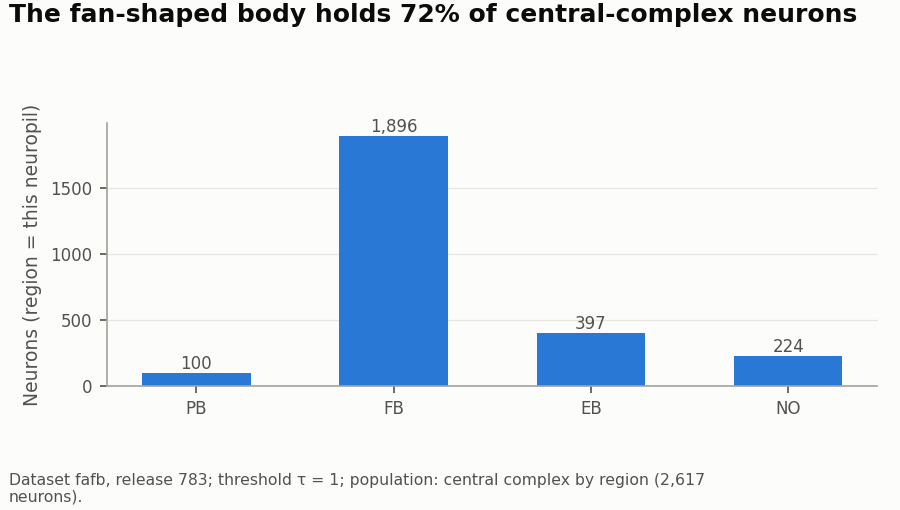

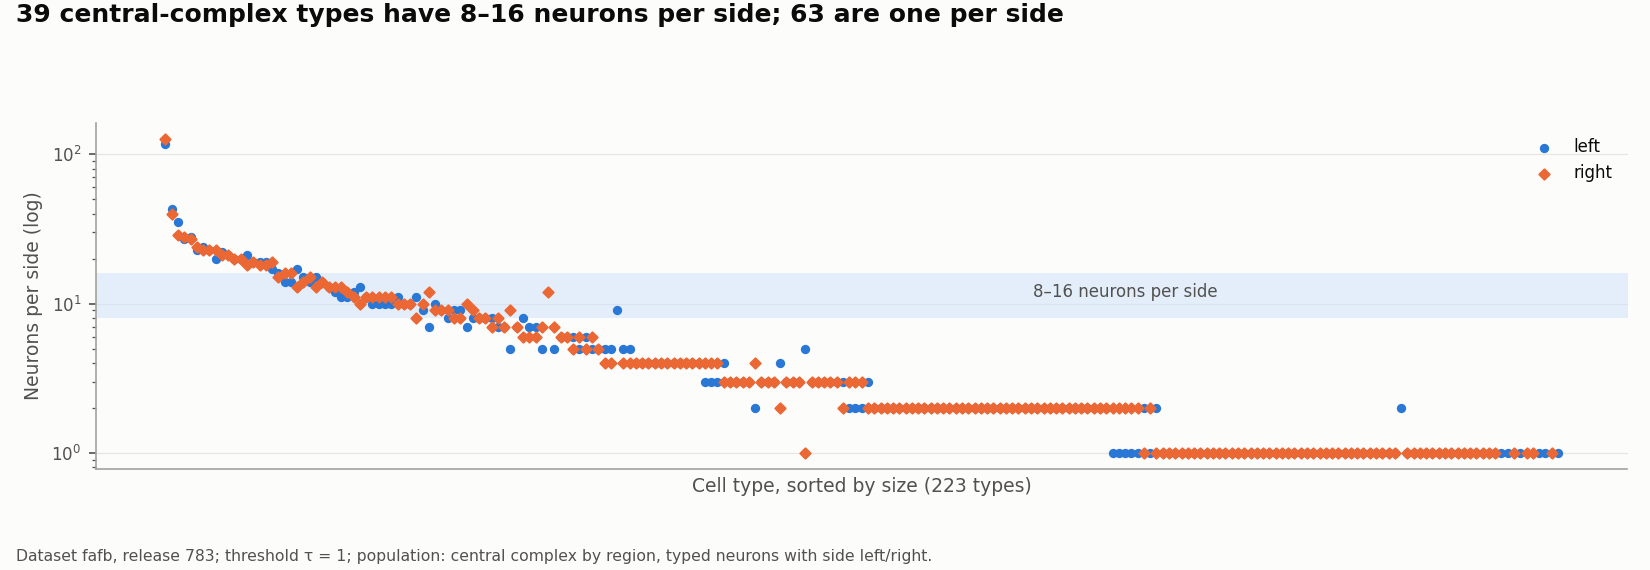

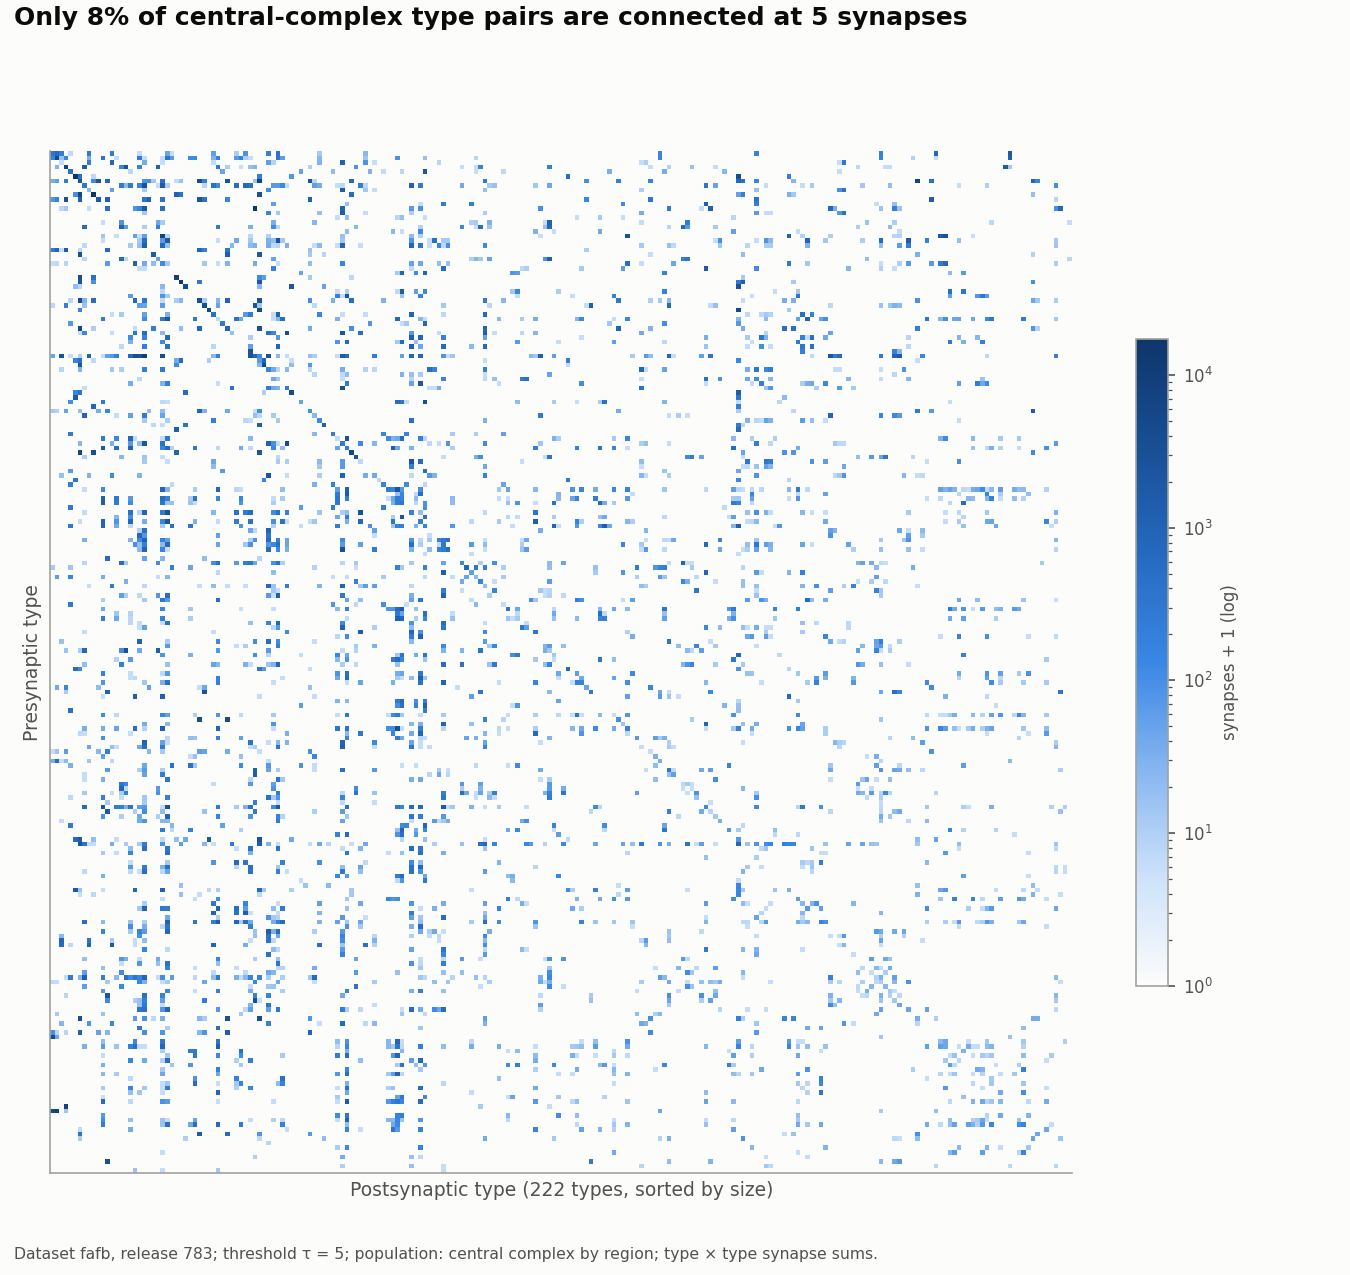

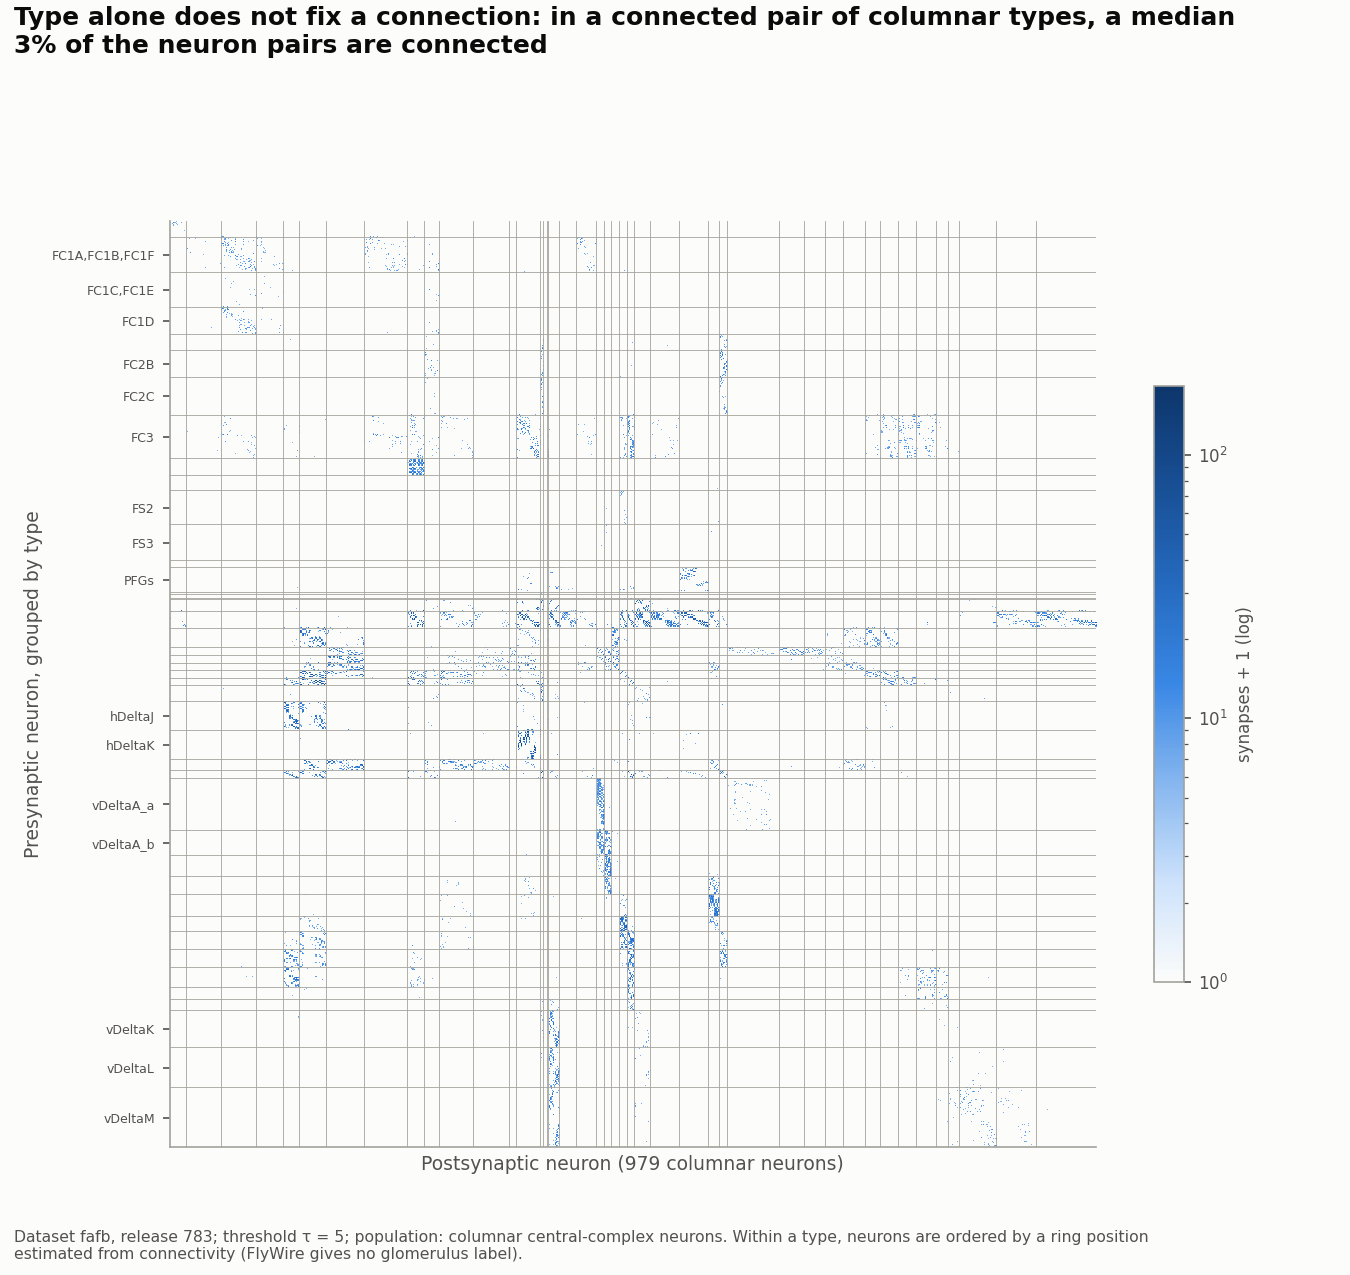

In [8]:
paths, st, tabs = F.fig_e7(neurons, edges)
STATS['E7'] = st
print(json.dumps(st, indent=1, default=float))
for p in paths:
    display(Image(filename=str(p)))

In [9]:
(ROOT / 'reports' / 'eda_E_stats.json').write_text(json.dumps(STATS, indent=1, default=float))

1268